# Week 07: Central limit theorem, confidence interval

**Course:** MATH7810 Python for Data Science (AY2026/27)

Open `W07_Ch4_SamplingShape_Demo.ipynb` first. The instructor runs that demonstration. This notebook is the practice that follows.

Three tasks, in order. Each uses an Input / Process / Output prompt. In Task 1 you write **Input**, **Process**, and **Output**. In Task 2 and Task 3, Input is filled in and you write Process and Output.


## Task 1 — central limit theorem

**Question:** Waiting time in the bank example is exponential with mean 10 minutes. One waiting time is right-skewed, not normal. If we take many samples, when does the histogram of the **sample means** look approximately normal?

Draw **2000** samples of size **5**, and **2000** samples of size **36** (size 36 is the sample size from the lecture example).

Write **Input**, **Process**, and **Output** yourself, then Inline Chat.

**Done when:** two histograms of sample means, each with a normal curve that has mean 10 and standard deviation $10/\sqrt{n}$. The $n = 36$ histogram sits closer to that curve than the $n = 5$ histogram.


In [ ]:
# Task 1 — central limit theorem
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: write a python program that demonstrates the central limit theorem by generating random samples from a uniform distribution and plotting the resulting sample means. The program should allow the user to specify the number of samples and the sample size.
#
#
# Process:write a python program that generates random samples from a uniform distribution, calculates the sample means, and plots the resulting sample means using matplotlib. The program should take user input for the number of samples and the sample size.
#
#
# Output: A histogram showing the distribution of the sample means, which should approximate a normal distribution according to the central limit theorem.
#
# --- End prompt ---
# Fill Input, Process and Output from the task. 
# Inline Chat (Cmd+I / Ctrl+I): implement the prompt in the comments. Keep.
#
# --- generated / your code below ---


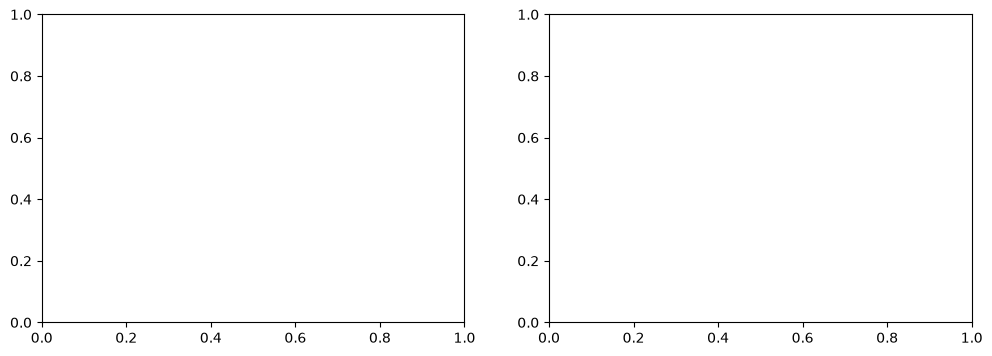

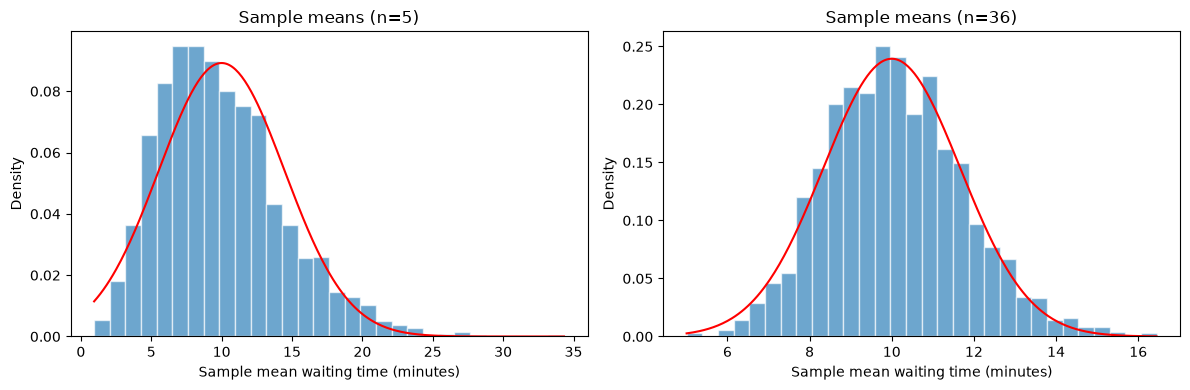

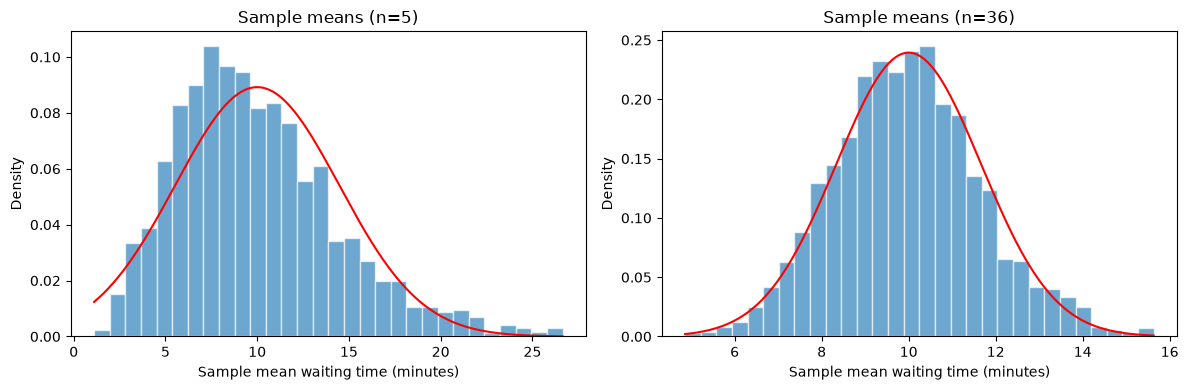

<Figure size 640x480 with 0 Axes>

In [3]:
import numpy as np
from scipy import stats

# Draw 2,000 samples for each sample size from an exponential population with mean 10.
sample_count = 2000
sample_sizes = [5, 36]

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, n in zip(axes, sample_sizes):
    import matplotlib.pyplot as plt

    # Draw 2,000 samples for each sample size from an exponential population with mean 10.
    sample_count = 2000
    sample_sizes = [5, 36]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, n in zip(axes, sample_sizes):
        sample_means = np.random.exponential(
            scale=10, size=(sample_count, n)
        ).mean(axis=1)

        ax.hist(sample_means, bins=30, density=True, alpha=0.65, edgecolor="white")
        x = np.linspace(sample_means.min(), sample_means.max(), 300)
        ax.plot(x, stats.norm.pdf(x, loc=10, scale=10 / np.sqrt(n)), color="red")
        ax.set_title(f"Sample means (n={n})")
        ax.set_xlabel("Sample mean waiting time (minutes)")
        ax.set_ylabel("Density")

    plt.tight_layout()
    plt.show()

    ax.hist(sample_means, bins=30, density=True, alpha=0.65, edgecolor="white")
    x = np.linspace(sample_means.min(), sample_means.max(), 300)
    ax.plot(x, stats.norm.pdf(x, loc=10, scale=10 / np.sqrt(n)), color="red")
    ax.set_title(f"Sample means (n={n})")
    ax.set_xlabel("Sample mean waiting time (minutes)")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

**Check:** The population of waiting times is still exponential. Which histogram of **sample means** is closer to a normal curve, and why? Type in the next cell, then **run** it.


In [5]:
print(
    "The histogram for n = 36 is closer to a normal curve. "
    "By the central limit theorem, sample means become more nearly normal "
    "as the sample size increases, even though the waiting times themselves "
    "have an exponential distribution."
)

The histogram for n = 36 is closer to a normal curve. By the central limit theorem, sample means become more nearly normal as the sample size increases, even though the waiting times themselves have an exponential distribution.


## Task 2 — confidence interval for the population mean, population $\sigma$ unknown

Run the setup cell first. It loads `checkout_lab.csv`.

`purchased` is 1 or 0. `order_value` is missing when `purchased` is 0.

**Question:** Among visits **with a purchase**, what is a **95% confidence interval for the population mean** order value?

The population standard deviation of order value is not known. Use a $t$ interval.

**Done when:** the cell prints the sample size, the sample mean, and the two endpoints.


In [1]:
# Setup for Task 2 and Task 3. 
import numpy as np
from scipy import stats
import pandas as pd

# checkout_lab.csv is in the week07 folder, next to this notebook.
# One row is one visit. Task 2 and Task 3 use this table.
visits = pd.read_csv("checkout_lab.csv")

# shape is (number of rows, number of columns). head() prints the first five rows.
print("rows, columns:", visits.shape)
print(visits.head())


rows, columns: (500, 6)
  checkout_page  order_value  purchased gender browser  time_on_page
0             B        24.97          1      F  chrome         36.30
1             C        39.32          1      F  chrome         51.13
2             C        38.03          1      M  safari         48.56
3             C        25.87          1      M  chrome         24.23
4             B        20.41          1      F  safari         30.21


In [ ]:
# Task 2 — confidence interval for the population mean
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: write a python program that calculates the 95% confidence interval for the population mean of the waiting times in the checkout_lab.csv dataset. The program should use the sample mean and standard deviation to compute the confidence interval.
#
#
# Process:write a python program that reads the checkout_lab.csv dataset, calculates the sample mean and standard deviation of the waiting times, and then computes the 95% confidence interval for the population mean using the t-distribution.
#
#
# Output:write the 95% confidence interval for the population mean of the waiting times in the checkout_lab.csv dataset.
#
# --- End prompt ---
# Fill Process and Output from the task. Highlight this comment block.
# Inline Chat (Cmd+I / Ctrl+I): implement the prompt in the comments. Keep.
#
# --- generated / your code below ---


In [3]:
# Task 2 — confidence interval for the population mean
# Use order values from visits that resulted in a purchase.
order_values = visits.loc[visits["purchased"] == 1, "order_value"].dropna()

n = len(order_values)
sample_mean = order_values.mean()
sample_sd = order_values.std(ddof=1)
critical_value = stats.t.ppf(0.975, df=n - 1)
margin_of_error = critical_value * sample_sd / np.sqrt(n)

ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

print(f"Sample size: {n}")
print(f"Sample mean order value: ${sample_mean:.2f}")
print(f"95% t confidence interval: (${ci_lower:.2f}, ${ci_upper:.2f})")

Sample size: 423
Sample mean order value: $30.24
95% t confidence interval: ($29.55, $30.93)


If we repeat the same sampling and calculation process 100 times, about 95 of those intervals will contain the true population mean and 5 will not.

## Task 3 — confidence interval for the population proportion

Use the same `visits` table from the setup cell.

**Question:** Among **all visits in this file**, what is a **95% confidence interval for the population proportion** who purchased?

Use a $z$ interval.

**Done when:** the cell prints the sample size, the sample proportion, and the two endpoints.
